In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cuda")
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import optuna

import pyrite

optuna.logging.set_verbosity(optuna.logging.WARNING)
with mo.status.spinner(title="Preparing PyRITE reference tables"):
    _ = pyrite.fetch_tables()
tables_ready = True

# Tuning CUDA execution

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/15-tuning-cuda-execution.py)

A simulation has two phases: **electron transport**, then **spectrum
scoring** of the transported segments. Their execution controls are
independent, so PyRITE tunes them as two separate studies:

- **Transport** candidates (electron batch, continuation schedule) run
  *only* transport and must reproduce the baseline's transported arrays
  bit for bit.
- **Spectrum** candidates (CXR segment chunk) rescore *one* kept transport
  without transporting again, and must reproduce its spectra.

Each study tries every valid combination of its own controls, then re-times
the fastest against the baseline before accepting it. On this workload the
whole tuning takes a few minutes; the spectrum phase dominates the run, and
its default chunk is already at its cap, so expect the transport study to
find more than the spectrum study.

This tutorial **needs an NVIDIA GPU**; on Molab, choose a GPU runtime. The
tuner, `pyrite.phases` and `TransportKernelTuning` are experimental.
Timings depend on the device, driver, precision and the other work on the
machine.

In [ ]:
from pyrite import Scene
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

scene = Scene(
    Beam(kinetic_energy=30 * ureg.keV, transverse=PointSpot(), longitudinal=PointBunch()),
    Slab(
        "hopg",
        thickness=5 * ureg.um,
        tilt=45 * ureg.degree,
        footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
    ),
    Detector(observation_angle=90 * ureg.degree),
    numerics=Numerics(
        sampling=FixedSampling(cxr_electrons=16_384, brem_electrons=1_024),
        seed=7,
        energy_bins=EnergyBins().with_cxr_energies(np.linspace(750, 1_000, 251) * ureg.eV),
        cxr_reflections=CxrReflections(n_families=1),
    ),
)

## Where the time goes

`simulate_transport` stops after transport; `score_spectra` scores the
kept segments. Timing them separately shows which phase is worth tuning.
Both report progress after every transport batch and spectrum stage; the
same `progress=` callback works on `pyrite.simulate`.

In [ ]:
from time import perf_counter

from pyrite.phases import score_spectra, simulate_transport

assert tables_ready
with mo.status.progress_bar(total=100, title="One untimed run, then timed phases") as _bar:

    def show(event):
        _bar.update(
            increment=0,
            subtitle=f"{event.phase}: {event.stage} {event.done:,}/{event.total:,}",
        )

    score_spectra(simulate_transport(scene))  # compile kernels first
    _started = perf_counter()
    transported = simulate_transport(scene, progress=show)
    _bar.update(increment=50)
    transport_s = perf_counter() - _started
    _started = perf_counter()
    _ = score_spectra(transported, progress=show)
    _bar.update(increment=50)
    spectrum_s = perf_counter() - _started
del transported  # releases the kept segments on the device

In [ ]:
mo.md(
    f"Transport **{transport_s:.2f} s**, spectrum **{spectrum_s:.2f} s** "
    f"({spectrum_s / (transport_s + spectrum_s):.0%} of the run)."
)

Transport **1.17 s**, spectrum **5.21 s** (82% of the run).

In [ ]:
from pyrite.optimization import KernelSearchSpace, tune_kernels

space = KernelSearchSpace(
    electron_batch=(None, 4_096, 16_384),
    schedule=("full-history", "auto"),
    cxr_chunk=(16_384, 65_536, 262_144),
)
_candidates = sum(
    len(space.choices(scene.numerics.kernel_tuning, p)) for p in ("transport", "spectrum")
)
with mo.status.progress_bar(
    total=_candidates + 2, title="Tuning transport, then spectrum", show_eta=True
) as _bar:

    def advance(update):
        if update.simulation is not None:
            _sim = update.simulation
            _detail = f"run {update.run}/{update.runs}: {_sim.stage} {_sim.done:,}/{_sim.total:,}"
        else:
            _detail = update.state
        _finished = update.state in ("baseline", "complete", "rejected")
        _bar.update(
            increment=1 if _finished else 0,
            subtitle=f"{update.phase} {update.trial}/{update.trials} — {_detail}",
        )

    tuning = tune_kernels(scene, space, warmups=1, repeats=3, on_progress=advance)

In [ ]:
def describe(trial, phase):
    if phase == "transport":
        t = trial.tuning.transport
        values = {"batch": t.electron_batch, "schedule": t.schedule}
    else:
        values = {"cxr chunk": trial.tuning.cxr_chunk}
    return ", ".join(f"{k} {'default' if v is None else v}" for k, v in values.items())


def table(study):
    _rows = [
        f"### {study.phase.capitalize()}: synchronized phase seconds",
        "| Trial | Settings | Median (s) | Outcome |",
        "|---:|---|---:|---|",
        f"| baseline | {describe(study.baseline, study.phase)} "
        f"| {study.baseline.median_s:.3f} | reference |",
    ]
    for _trial in study.trials:
        if _trial.tuning is None or _trial.repeat_of is not None:
            continue
        _time = "—" if _trial.median_s is None else f"{_trial.median_s:.3f}"
        _outcome = "accepted" if _trial.state == "complete" else f"rejected: {_trial.reason}"
        _rows.append(
            f"| {_trial.number} | {describe(_trial, study.phase)} | {_time} | {_outcome} |"
        )
    _verdict = "confirmed" if study.improved else "kept the baseline"
    _rows.append(
        f"\n**Chosen:** {describe(study.chosen, study.phase)} ({_verdict}); "
        f"**{study.speedup:.2f}×** the baseline phase median."
    )
    return "\n".join(_rows)


# Each phase's speedup weighted by its share of the run timed above.
_whole = (transport_s + spectrum_s) / (
    transport_s / tuning.transport.speedup + spectrum_s / tuning.spectrum.speedup
)
_env = ", ".join(f"{k} `{v}`" for k, v in tuning.environment.items())
mo.md(
    f"Measured on {_env}.\n\n"
    + "\n\n".join(table(_study) for _study in tuning.phases)
    + f"\n\n**Estimated whole-run speedup: {_whole:.2f}×** — a phase's gain counts "
    "only in proportion to its share of the run."
)

Measured on backend `cuda`, device `NVIDIA GeForce RTX 5080`, precision `fp32`, pyrite_version `0.24.0`, cupy `14.2.0`, cuda_runtime `13020`, cuda_driver `13030`.

### Transport: synchronized phase seconds
| Trial | Settings | Median (s) | Outcome |
|---:|---|---:|---|
| baseline | batch default, schedule default | 1.273 | reference |
| 0 | batch default, schedule full-history | 0.866 | accepted |
| 1 | batch default, schedule auto | 1.101 | accepted |
| 2 | batch 4096, schedule full-history | 1.029 | accepted |
| 3 | batch 4096, schedule auto | 1.276 | accepted |
| 4 | batch 16384, schedule full-history | 0.916 | accepted |
| 5 | batch 16384, schedule auto | 1.101 | accepted |

**Chosen:** batch default, schedule full-history (confirmed); **1.37×** the baseline phase median.

### Spectrum: synchronized phase seconds
| Trial | Settings | Median (s) | Outcome |
|---:|---|---:|---|
| baseline | cxr chunk default | 4.993 | reference |
| 0 | cxr chunk 16384 | 10.754 | accepted |
| 1 | cxr chunk 65536 | 5.024 | accepted |
| 2 | cxr chunk 262144 | 5.054 | accepted |

**Chosen:** cxr chunk default (kept the baseline); **1.00×** the baseline phase median.

**Estimated whole-run speedup: 1.05×** — a phase's gain counts only in proportion to its share of the run.

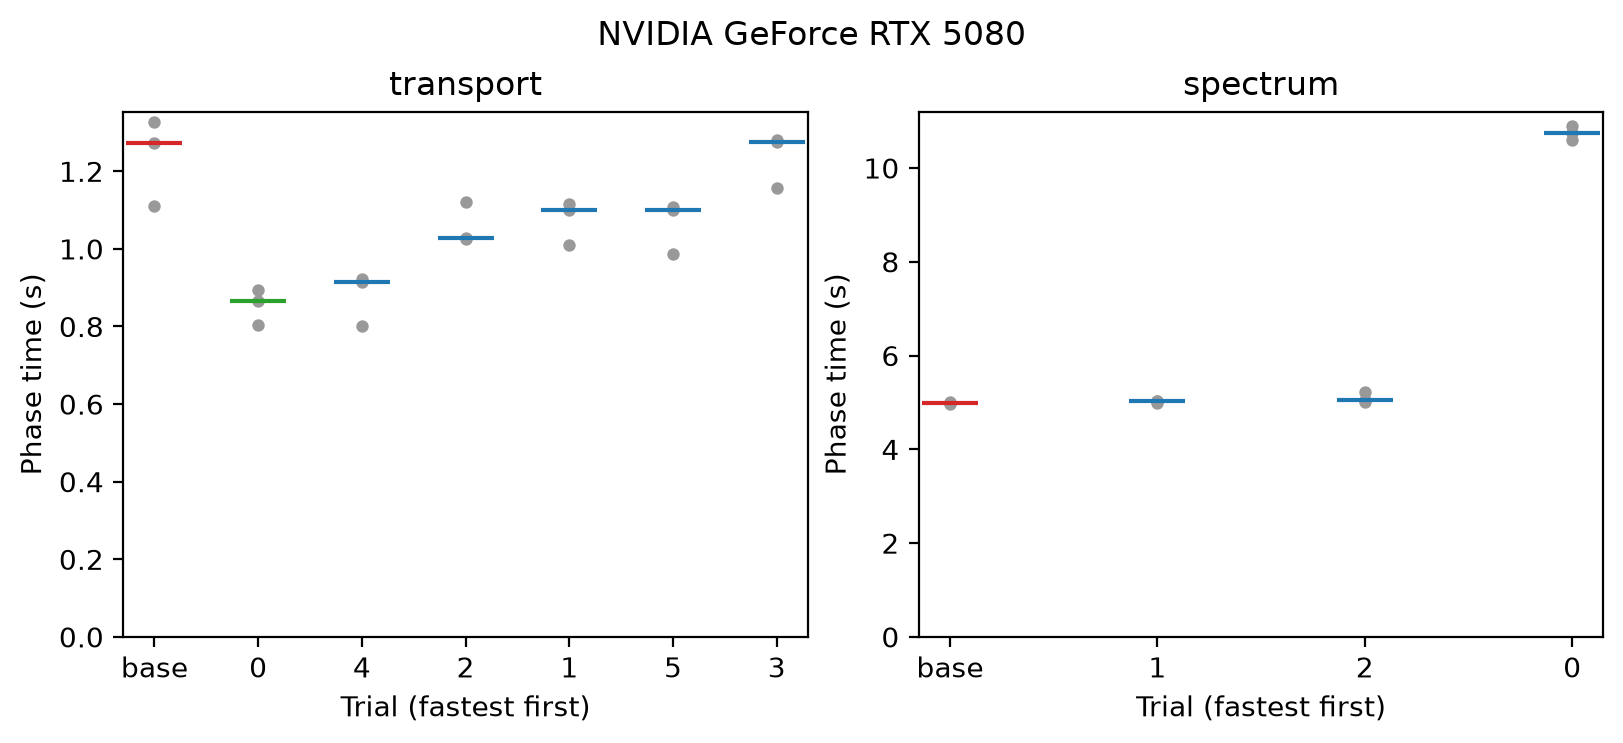

In [ ]:
fig_timing, _axes = plt.subplots(
    1, len(tuning.phases), figsize=(8, 3.6), layout="constrained", squeeze=False
)
for _ax, _study in zip(_axes[0], tuning.phases, strict=True):
    _done = [t for t in _study.trials if t.state == "complete" and t.repeat_of is None]
    _shown = [_study.baseline, *sorted(_done, key=lambda t: t.median_s)]
    for _i, _trial in enumerate(_shown):
        _samples = np.asarray(_trial.samples_s)
        _ax.scatter(np.full(_samples.size, _i), _samples, color="0.6", s=12)
        _colour = "C3" if _i == 0 else ("C2" if _trial is _study.chosen else "C0")
        _ax.scatter(_i, np.median(_samples), color=_colour, marker="_", s=400)
    _ax.set(
        xticks=range(len(_shown)),
        xticklabels=["base", *(str(t.number) for t in _shown[1:])],
        xlabel="Trial (fastest first)",
        ylabel="Phase time (s)",
        title=_study.phase,
    )
    _ax.set_ylim(bottom=0)
fig_timing.suptitle(tuning.environment.get("device", "GPU"))
fig_timing  # noqa: B018

## Apply and check the joined winner

`tuning.best` joins the transport winner's controls with the spectrum
winner's chunk. Applying it through ordinary `Numerics` must leave the
spectrum unchanged up to the summation-order differences a chunk change
can introduce.

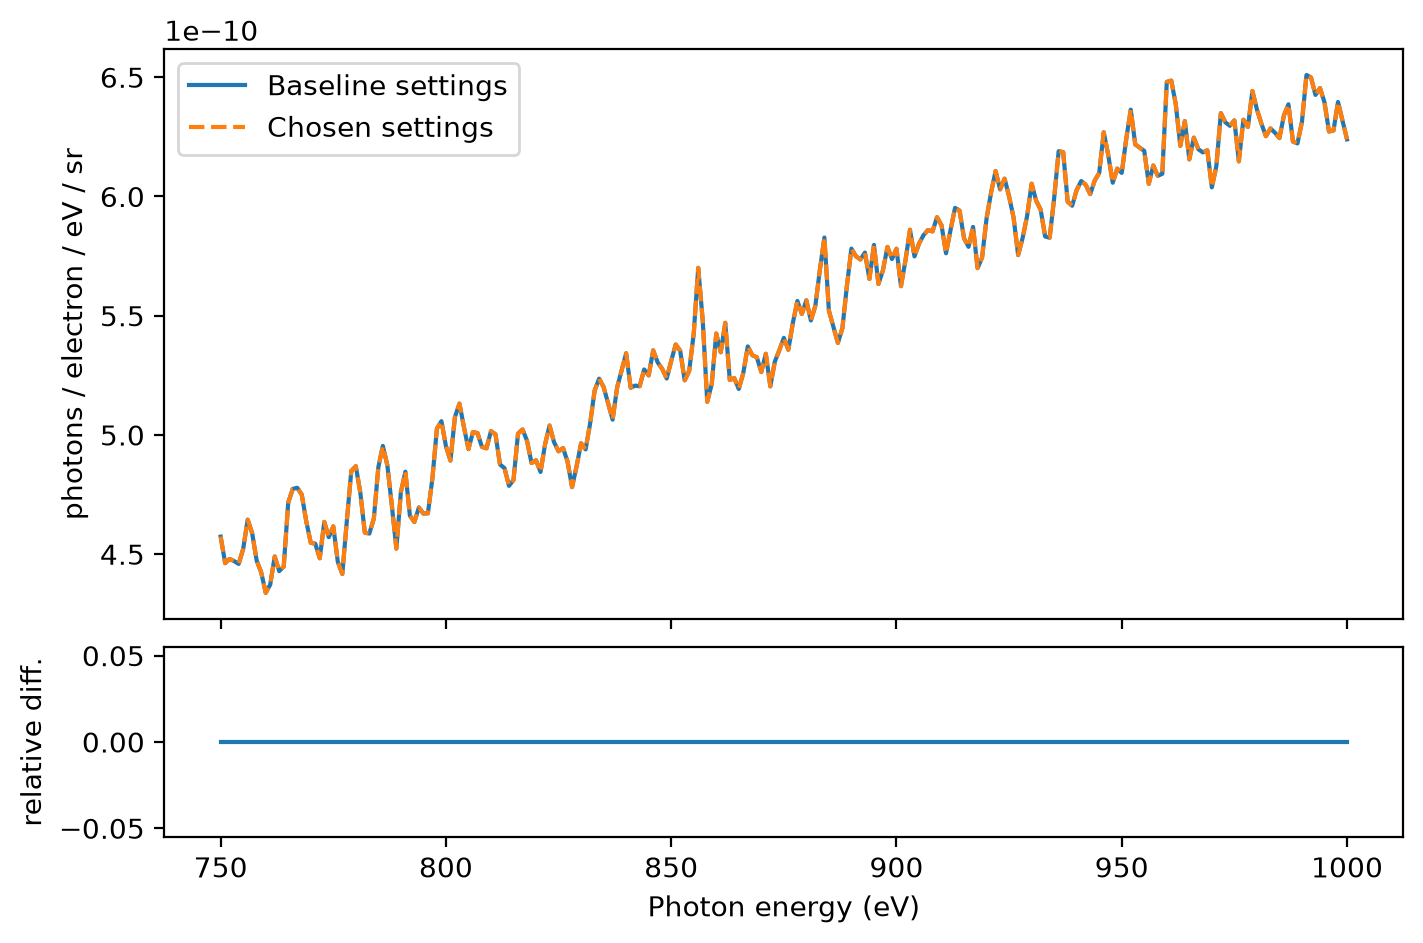

In [ ]:
with mo.status.progress_bar(total=2, title="Checking spectra after tuning") as _progress:
    baseline_result = pyrite.simulate(scene)
    _progress.update(subtitle="Original configuration")
    tuned_result = pyrite.simulate(scene, numerics=scene.numerics.with_kernel_tuning(tuning.best))
    _progress.update(subtitle="Joined transport + spectrum winners")
_energy = baseline_result.cxr.incoherent.photon_energy_eV
_base = baseline_result.cxr.incoherent.density
_tuned = tuned_result.cxr.incoherent.density
assert np.array_equal(_energy, tuned_result.cxr.incoherent.photon_energy_eV)
assert np.allclose(_tuned, _base, rtol=1e-4, atol=1e-12)
_floor = 1e-6 * np.abs(_base).max()
_relative = (_tuned - _base) / np.maximum(np.abs(_base), _floor)

fig_check, (_top, _bottom) = plt.subplots(
    2, 1, figsize=(7, 4.6), sharex=True, layout="constrained", height_ratios=(3, 1)
)
_top.plot(_energy, _base, label="Baseline settings")
_top.plot(_energy, _tuned, "--", label="Chosen settings")
_top.set(ylabel="photons / electron / eV / sr")
_top.legend()
_bottom.plot(_energy, _relative)
_bottom.set(xlabel="Photon energy (eV)", ylabel="relative diff.")
fig_check  # noqa: B018

## What the numbers mean

Every candidate runs in one CUDA **worker process** that compiles kernels
and loads tables once and releases the device memory pool before each
candidate; `isolate="candidate"` restarts it per candidate instead, at a
large cost. A candidate gets one untimed warm-up and three synchronized
timed runs of its phase. The fastest accepted candidate is then re-timed
in three interleaved pairs with the baseline, and replaces it only for at
least a 2% confirmed gain (`min_speedup`). A "kept the baseline" verdict
means the defaults were already as fast on this workload, not that tuning
failed.

The transport timer includes trajectory setup and automatic line-grid
resolution; the spectrum timer includes CXR, characteristic and
bremsstrahlung scoring. Neither isolates one kernel launch. The equality
checks are a tuning guard, not scientific validation. Winners are GPU-,
driver- and workload-specific: re-tune for a production workload, and
apply `scene.numerics.with_kernel_tuning(tuning.best)` in a new process.

## Continue learning

The [CUDA execution tuning how-to](../../guides/batch-chunk-tuning.md) applies a
winner and covers the CLI and Molab runs; the
[execution and acceleration explanation](../../computation/execution-and-acceleration.md)
describes each control and its defaults. The
[experimental API reference](../../reference/python-api/experimental.md#cuda-execution-tuning)
lists `tune_kernels`, `KernelSearchSpace` and `TransportKernelTuning`.

{download}`Download canonical Marimo notebook <../15-tuning-cuda-execution.py>`